### Vybhav Reddy

# Finding the Best Neighborhood in Pittsburgh: 311 Data

## How many 311 calls are are made per person in a neighborhood

I chose **311 Calls** as my submetric and suplemented it with **Population**, as the higher the 311 calls the more issues in the neighborhood like potholes and graffiti and in order to balance the calls from larger neighborhoods, I divided the 311 calls by population

Using data from **Western Pennsylvania Regional Data Center (WPRDC)**, **Pandas**, and **MatPlotLib**, I sorted through the data and graphed it to show the range of 311 calls.

## Importing and Loading

The first thing I did was import both pandas and matplotlib and add my 2 files

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("5202679a-d243-402e-b82a-63189995a942.csv", low_memory=False)
pop = pd.read_csv("preliminarycitypittsburghneighborhood_pl94171summary-2.csv")

## Cleaning the Data

I first removed all the points missing a neighborhood and the neighborhoods that did not exist in the population file. Then I changed the names in the 311 data's neighborhood column to match the names in the population file.

In [2]:
df["neighborhood"] = df["neighborhood"].str.strip()
df = df[df["neighborhood"].notna() & (df["neighborhood"] != "")]
df = df[df["neighborhood"] != "Mount Oliver Borough"]
df = df[~df["neighborhood"].str.startswith("Block Group")]   

df["neighborhood"] = df["neighborhood"].replace({
    "Arlington": "Arlington - Arlington Heights (Combined)",
    "Arlington Heights": "Arlington - Arlington Heights (Combined)",
    "Central Business District": "Central Business District (Downtown)",
    "Spring Hill-City View": "Spring Hill-City",
    "Southside Flats": "South Side Flats",        
    "Southside Slopes": "South Side Slopes",      
})

## Finding the 311 per Person

I took just the neighborhood and population from the population file and grouped my 311 call by neighborhood and found the requests per person

In [3]:
pop = pop[["Neighborhood", "2020_Total_Population"]].dropna()
pop.columns = ["neighborhood", "population"]

counts = df.groupby("neighborhood").size().reset_index(name="requests")
merged = counts.merge(pop, on="neighborhood")
merged["requests_per_Person"] = merged["requests"] / merged["population"]

print(merged.sort_values("requests_per_Person"))

         neighborhood  requests  population  requests_per_Person
56  Northview Heights      1040        1769             0.587903
34         Glen Hazel       609         659             0.924127
54      North Oakland     10086       10691             0.943410
9               Bluff      6045        5882             1.027712
81    Terrace Village      2824        2320             1.217241
..                ...       ...         ...                  ...
71  South Side Slopes     37297        4327             8.619598
55        North Shore      3112         301            10.338870
85           West End      2224         205            10.848780
69        South Shore      1708          29            58.896552
20            Chateau      2051          19           107.947368

[89 rows x 4 columns]


## Graphing

I removed the locations with under under 200 population as their 311 per person value was way to high and woul shift the graph drastically.

From this data we can see that the neighborhoods with the most 311 calls per person are West End and North Shore while the best neighborhoods, the ones with the least 311 calls, are Northview Heights and Glen Hazel

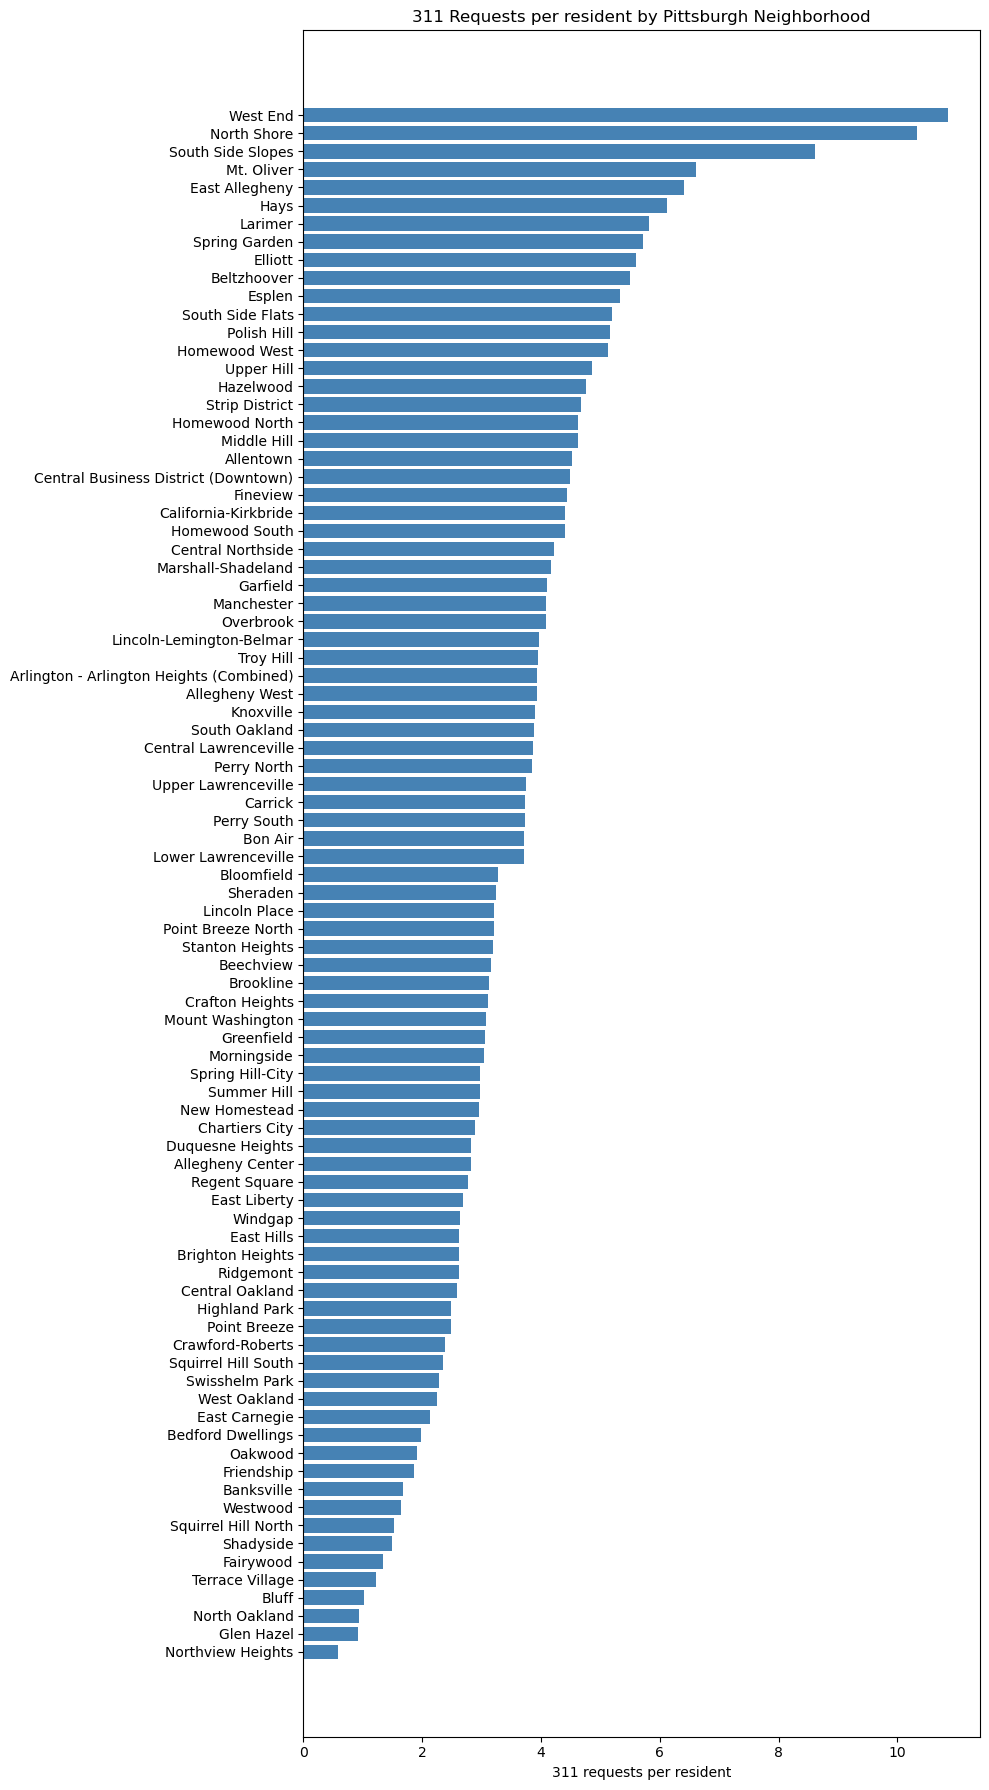

In [4]:
chart_data = merged[merged["population"] >= 200]

chart_data = chart_data.sort_values("requests_per_Person")

plt.figure(figsize=(10, 18))
plt.barh(chart_data["neighborhood"], chart_data["requests_per_Person"], color="steelblue")
plt.xlabel("311 requests per resident")
plt.title("311 Requests per resident by Pittsburgh Neighborhood")
plt.tight_layout()
plt.show()

## Conclusion

My data is based not on calls my by people that live in the neighborhood but rather calls made about issues in the neighborhood. Because of this neighborhoods with a less people may get a much higher rating than they should because of calls made from people who dont live in the neighborhood. However, even with that, this still gives a somewhat accurate showcase of the number of 311 calls per person especially in the larger neighborhoods.